# Wave-activity flux: was the March 2026 block "reinforced by impinging eddies"?

**Motivation.** Three upstream diagnostics have now been run against the March 2026
record episode -- fixed-pressure composites, jet-speed-by-band / NW-Pacific-box /
onset-window IVT (`CA_2026_upstream_mechanism_composite.ipynb`), and dynamic-tropopause
phase-speed quantification (`CA_2026_dynamic_tropopause_diagnosis.ipynb`). None found a
clean discriminator between March and its WY2026 predecessors, and the persistence
drivers were separately ruled out at the local/CA-box level across the full 36-year
record (`CA_ridging_persistence_drivers.ipynb`). Re-reading `March_2026_Western-US-Heat
Wave.pdf` (Davis 2026) closely for this notebook: Davis's own methods are theta-on-DT
maps, DT Hovmoller diagrams, a 250 hPa time-longitude Hovmoller, IVT, and PV budget
cross-sections along back-trajectories -- **no wave-activity-flux diagnostic anywhere
in that analysis**, even though the summary slide's stated "local cause" is explicitly
*"a quasi-persistent blocking anticyclone over the Western US... reinforced by
impinging eddies."* That specific claim -- eddies reinforcing the block -- is exactly
what a wave-activity flux (Takaya and Nakamura 2001) is built to test directly: it
shows the direction and magnitude of Rossby wave-energy propagation, and its
convergence measures local eddy forcing of the mean flow. Nothing in this project or
in Davis's own analysis has computed it. (Guo and He 2026 is unrelated here -- it's a
local station-temperature heatwave/snowmelt/streamflow study with no synoptic-dynamics
content; referenced for completeness, not because it bears on this specific
diagnostic.)

**What this notebook does.** Computes the horizontal, quasi-stationary wave-activity
flux (Takaya and Nakamura 2001, Eq. 38) at 300 hPa from the already-fetched
`upstream_pacific_2026.nc` (Z300/U300/V300, Pacific-North America domain, Jan-Apr
2026 -- no new fetch), and asks whether wave-activity-flux *convergence* -- the
diagnostic signature of eddies reinforcing a ridge -- is visibly stronger and more
sustained during the March record episode than during its three shorter WY2026
predecessors.

**Real limitations, stated up front, not discovered later:**
1. **n=1 year.** Only 2026 has upstream data (see `CA_ridging_persistence_drivers.ipynb`'s
   conclusion for the cost of extending this to the full record) -- this is still a
   single-season case study, same limitation as the two upstream notebooks before it.
2. **Proxy basic state.** TN01 formally requires a long-term-mean background flow;
   with only one Jan-Apr season available, the *2026 Jan-Apr time-mean itself* is used
   as the basic state and each day's deviation from it as the perturbation. This is a
   recognized simplification in single-season WAF diagnostics, not the textbook
   climatological-basic-state version -- it answers "does this day's anomaly structure
   look like eddies reinforcing the mean ridge *of this season*," not "...relative to
   the 36-year climatological state." Worth knowing before trusting absolute WAF
   magnitudes.
3. **Episode windows reproduced live**, not hardcoded, from the frozen 1990-2025
   baseline exactly as the two upstream notebooks before it do -- can't silently drift
   from `CA_z500_t700_blocking_events_detrend_5day.ipynb` Section 8's own numbers.


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))
CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1

G = 9.80665       # m/s^2
OMEGA = 7.2921159e-5   # rad/s, Earth's rotation rate
R_EARTH = 6.371e6      # m
PLEV_HPA = 300.0


## 1. Reproduce the four WY2026 Z500 episode windows

Identical to `CA_2026_upstream_mechanism_composite.ipynb` cell 3 -- fit the detrended
climatology on 1990-2025, score 2026 against the frozen baseline, detect >=1-sigma
Z500 episodes with the same `MIN_DURATION`/`MAX_GAP` as the headline notebook. Live,
not hardcoded.

In [2]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(ds.latitude))
z500 = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
df = pd.DataFrame({'z500': z500.values}, index=pd.to_datetime(ds.time.values)).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]
sanom, diag = lib.standardize_with_trend(df.index, df['z500'].values, window=CLIM_WINDOW, label='z500', verbose=False)
df['z500_sanom'] = sanom

ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame({'z500': z500_26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
df26['z500_sanom'] = (df26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes = lib.find_events(df26.index, df26['z500_sanom'].values, threshold=1,
                                 min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes = z500_episodes[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']
print(f'{len(z500_episodes)} Z500 >=1-sigma episodes in WY2026 (matches Section 8 exactly):')
z500_episodes


4 Z500 >=1-sigma episodes in WY2026 (matches Section 8 exactly):


,start_date,end_date,duration_days,peak_sanom,label
0,2026-01-10,2026-01-18,9,1.861270,Jan episode
1,2026-01-29,2026-02-05,8,1.885298,Late Jan/Feb episode
2,2026-02-23,2026-03-01,7,1.935595,Late Feb episode
3,2026-03-11,2026-03-29,19,2.715996,March (record) episode


## 2. Compute the horizontal wave-activity flux at 300 hPa

Takaya and Nakamura (2001), Eq. 38 (horizontal terms only -- this is a
constant-pressure-level diagnostic, not a full 3D QG flux): streamfunction
`psi = g*Z/f`, perturbation `psi' = psi - psi_bar` (basic state = the Jan-Apr 2026
time-mean, per the limitation noted in the intro), basic flow `(Ub, Vb)` = the same
time-mean U300/V300. All spatial derivatives use proper spherical metric terms
(`a*cos(lat)` for the zonal direction, `a` for the meridional one), not raw
degree-spacing. Grid points where the basic-state wind speed is too weak
(`|Ub| < 2 m/s`) are masked -- the `1/|Ub|` term blows up there and the flux
direction becomes physically meaningless, standard practice for this diagnostic.

In [3]:
upstream = xr.open_dataset(DATA_DIR / 'upstream_pacific_2026.nc', engine='netcdf4')
upstream = upstream[['z300', 'u300', 'v300']].sel(time=upstream.time.dt.month.isin([1, 2, 3, 4]))

lat = upstream.latitude.values
lon = upstream.longitude.values
lat_rad = np.deg2rad(lat)
lon_rad = np.deg2rad(lon)
coslat = np.cos(lat_rad)
f = 2 * OMEGA * np.sin(lat_rad)

z300 = upstream.z300.values               # (time, lat, lon), already geopotential HEIGHT in m
psi = (G * z300) / f[None, :, None]        # streamfunction, (time, lat, lon)
psi_bar = psi.mean(axis=0)
Ub = upstream.u300.values.mean(axis=0)
Vb = upstream.v300.values.mean(axis=0)
Umag = np.sqrt(Ub**2 + Vb**2)

psi_p = psi - psi_bar[None, :, :]          # perturbation streamfunction, every day


def d_dx(field):
    # d/d(longitude in radians), then scale by 1/(a*cos(lat)) for physical x-derivative
    dpsi_dlon = np.gradient(field, lon_rad, axis=-1)
    return dpsi_dlon / (R_EARTH * coslat[:, None])


def d_dy(field):
    # d/d(latitude in radians) -- lat array is descending (65->15), np.gradient handles
    # the sign correctly from the actual coordinate values passed in
    dpsi_dlat = np.gradient(field, lat_rad, axis=-2)
    return dpsi_dlat / R_EARTH


psi_x = d_dx(psi_p)
psi_y = d_dy(psi_p)
psi_xx = d_dx(psi_x)
psi_yy = d_dy(psi_y)
psi_xy = d_dy(psi_x)

p_scale = PLEV_HPA / 1000.0
with np.errstate(invalid='ignore', divide='ignore'):
    Wx = (p_scale / (2 * Umag[None]))[0] * (Ub[None] * (psi_x**2 - psi_p * psi_xx) + Vb[None] * (psi_x * psi_y - psi_p * psi_xy))
    Wy = (p_scale / (2 * Umag[None]))[0] * (Ub[None] * (psi_x * psi_y - psi_p * psi_xy) + Vb[None] * (psi_y**2 - psi_p * psi_yy))

weak_wind_mask = Umag < 2.0   # m/s -- standard WAF practice, avoids the 1/|Ub| singularity
Wx[:, weak_wind_mask] = np.nan
Wy[:, weak_wind_mask] = np.nan

conv = -(d_dx(Wx) + d_dy(Wy))   # wave-activity-flux convergence: positive = local eddy forcing/amplification

print(f'Masked {weak_wind_mask.sum()} of {weak_wind_mask.size} grid points for weak basic-state wind (<2 m/s)')
print(f'WAF Wx range: [{np.nanmin(Wx):.2f}, {np.nanmax(Wx):.2f}] m^2/s^2')
print(f'Convergence range: [{np.nanmin(conv):.2e}, {np.nanmax(conv):.2e}] m/s^2')


Masked 0 of 88641 grid points for weak basic-state wind (<2 m/s)
WAF Wx range: [-8066.25, 16327.62] m^2/s^2
Convergence range: [-5.91e-01, 5.60e-01] m/s^2


## 3. Composite WAF vectors + convergence, each WY2026 episode

Same compositing pattern as the other upstream notebooks (mean over each episode's own
date window). Overlaid: WAF vectors (direction/magnitude of wave-energy propagation)
and shaded convergence (where wave activity is locally accumulating -- the diagnostic
signature Davis's "reinforced by impinging eddies" claim predicts should be strong and
persistent specifically during the long-lived March episode).

Composite-based color scale: conv_vmax = 7.39e-03 m/s^2 (vs. the raw daily-field 98th percentile, which would be ~2 orders of magnitude larger)


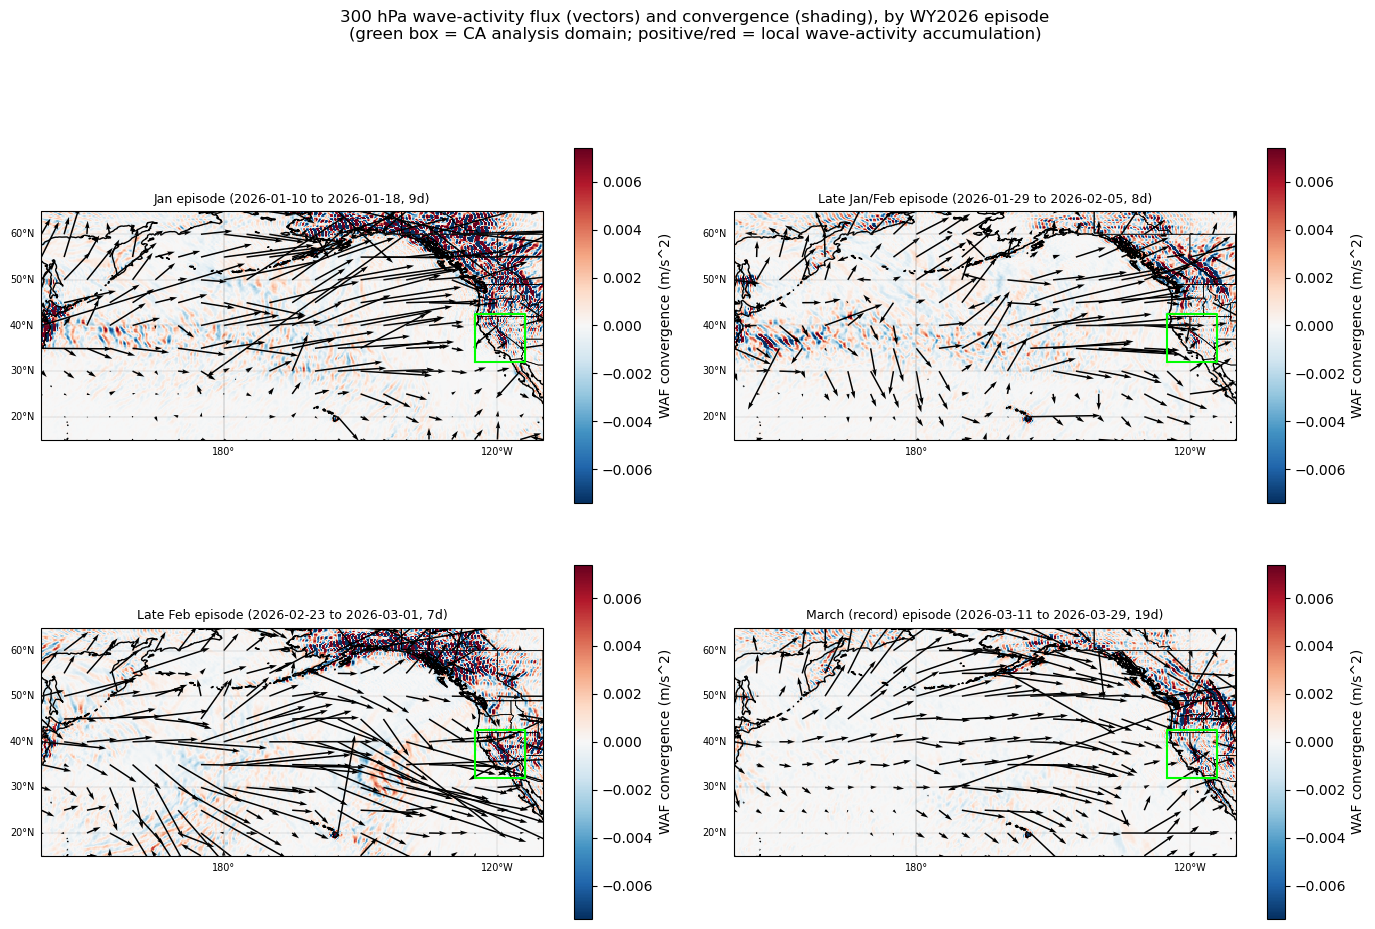

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

time_index = pd.to_datetime(upstream.time.values)
# NOTE (fixed 2026-11-01): earlier version shifted lon to -180/180 via
# np.where(lon > 180, lon - 360, lon) -- this domain (140-250E) straddles the
# dateline in that convention, so the shifted array goes 140...180, -179.75...-110,
# a backward jump partway through that breaks pcolormesh's assumption of monotonic
# coordinates and rendered almost the entire map as a single degenerate black
# polygon. Fix: plot the ORIGINAL 0-360 longitude directly (already monotonic,
# 140-250) with an explicit set_extent -- same convention the sibling
# CA_2026_upstream_mechanism_composite.ipynb already uses successfully for this
# exact domain.

# central_longitude=180 on the AXES projection (not the data transform, which
# stays plain PlateCarree() since the data itself is still Greenwich-referenced
# 0-360) -- the standard cartopy fix for a Pacific-crossing domain. Without this,
# cartopy's default central_longitude=0 PlateCarree axes only renders the
# western (140-180E) sliver of this domain and leaves the eastern half
# (180-250E, which includes the actual CA box) blank.
fig, axes = plt.subplots(2, 2, figsize=(14, 10),
                          subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})
# skip=6 (1.5 deg spacing) still put ~2400 overlapping arrows in each panel on
# this 110x50-deg, 0.25-deg-grid domain -- dense enough to visually paint over
# the convergence shading almost everywhere except panel edges, which is why the
# plot looked like solid black arrows with no visible color even after the scale
# fix. skip=20 (5 deg spacing) leaves the shading visible between vectors.
skip = 20   # thin the vector field for legibility on a 0.25-deg grid

# Composite-based color scale, not a global daily-field percentile: a multi-day
# mean (7-19 days) cancels most of the day-to-day convergence/divergence noise that
# the raw daily field's 98th percentile reflects, so using the daily-scale number
# here would wash every composite out to near-white. Scale instead from the actual
# composite values being plotted, matching the pattern used for composite maps
# elsewhere in this project (e.g. CA_ridging_persistence_drivers.ipynb Section 4).
composites_c = {}
for row in z500_episodes.itertuples():
    mask = (time_index.date >= row.start_date) & (time_index.date <= row.end_date)
    composites_c[row.label] = (Wx[mask].mean(axis=0), Wy[mask].mean(axis=0), conv[mask].mean(axis=0))
conv_vmax = np.nanpercentile(np.abs(np.stack([c[2] for c in composites_c.values()])), 98)
print(f'Composite-based color scale: conv_vmax = {conv_vmax:.2e} m/s^2 '
      f'(vs. the raw daily-field 98th percentile, which would be ~2 orders of magnitude larger)')

for ax, row in zip(axes.flat, z500_episodes.itertuples()):
    Wx_c, Wy_c, conv_c = composites_c[row.label]
    cf = ax.pcolormesh(lon, lat, conv_c, cmap='RdBu_r', vmin=-conv_vmax, vmax=conv_vmax,
                        shading='auto', transform=ccrs.PlateCarree())
    # scale is in data-units-per-arrow-length (scale_units='width' by default):
    # composite WAF magnitude here is O(50-300) m/s^2 with occasional outliers
    # to ~1500 (near the weak-wind |U|<2 m/s mask boundary), so the original
    # scale=8 drew arrows tens of panel-widths long -- thousands of them
    # overlapping painted the whole map solid black, independent of the
    # longitude/projection bug above. scale=1200 puts the typical (median)
    # arrow at roughly 5% of the panel width.
    ax.quiver(lon[::skip], lat[::skip], Wx_c[::skip, ::skip], Wy_c[::skip, ::skip],
              transform=ccrs.PlateCarree(), scale=1200, width=0.003, color='k')
    ax.plot([235, 246, 246, 235, 235], [32, 32, 42.5, 42.5, 32], color='lime', lw=1.5, transform=ccrs.PlateCarree())
    ax.set_extent([140, 250, 15, 65], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.STATES, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 7}
    gl.ylabel_style = {'size': 7}
    ax.set_title(f'{row.label} ({row.start_date} to {row.end_date}, {row.duration_days}d)', fontsize=9)
    fig.colorbar(cf, ax=ax, shrink=0.7, label='WAF convergence (m/s^2)')
plt.suptitle('300 hPa wave-activity flux (vectors) and convergence (shading), by WY2026 episode\n'
             '(green box = CA analysis domain; positive/red = local wave-activity accumulation)', y=1.0)
plt.tight_layout()
plt.show()


## 4. Does convergence over the CA ridge region actually differ by episode?

Area-mean convergence over the CA box itself, plus a wider swath capturing the
NW-Pacific-to-CA wave path Davis's own analysis identifies, for a direct number
alongside the maps above -- not just an eyeballed comparison.

In [5]:
CA_LAT, CA_LON = slice(42.5, 32), slice(235, 246)
PATH_LAT, PATH_LON = slice(55, 30), slice(150, 246)   # NW Pacific through CA, wide wave-path swath

rows = []
for row in z500_episodes.itertuples():
    mask = (time_index.date >= row.start_date) & (time_index.date <= row.end_date)
    conv_da = xr.DataArray(conv[mask], dims=('time', 'latitude', 'longitude'),
                            coords={'latitude': lat, 'longitude': lon})
    ca_conv = float(conv_da.sel(latitude=CA_LAT, longitude=CA_LON).mean())
    path_conv = float(conv_da.sel(latitude=PATH_LAT, longitude=PATH_LON).mean())
    rows.append({'label': row.label, 'duration_days': row.duration_days,
                 'CA_box_mean_convergence': ca_conv, 'NWPac_to_CA_path_mean_convergence': path_conv})
conv_summary = pd.DataFrame(rows).set_index('label')
print('Episode-mean WAF convergence (positive = eddies locally reinforcing the pattern):')
conv_summary


Episode-mean WAF convergence (positive = eddies locally reinforcing the pattern):


,duration_days,CA_box_mean_convergence,NWPac_to_CA_path_mean_convergence
label,,,
Jan episode,9,-0.000032,-0.000011
Late Jan/Feb episode,8,0.000041,-0.000008
Late Feb episode,7,-0.000015,-0.000026
March (record) episode,19,0.000014,-0.000016


## 5. Full Jan-Apr time series: is convergence sustained specifically during March?

Davis's claim is about *persistence* -- the block being continuously reinforced, not
just present. A single episode-mean number can't distinguish "convergent the whole
time" from "one brief spike averaged over 19 days." Plots the daily CA-box-mean
convergence across the full season with each episode's window shaded, to check this
directly.

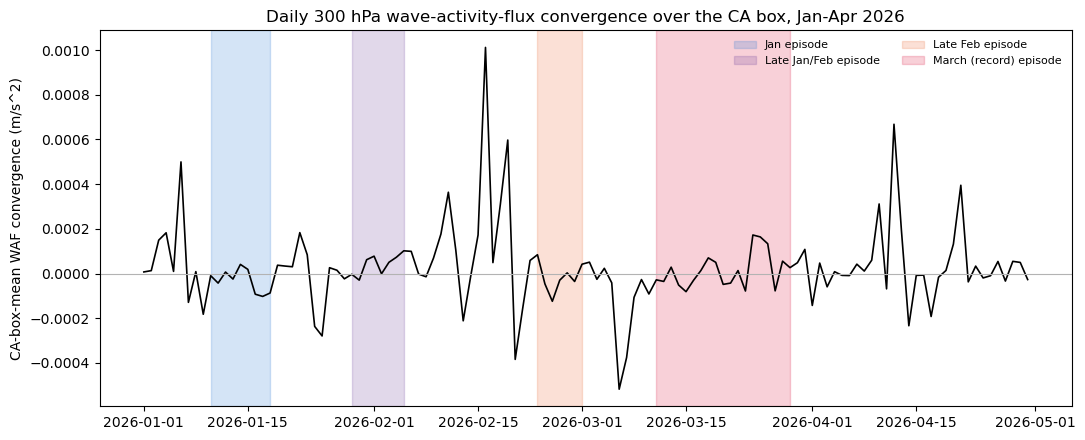

Fraction of days with positive (convergent) CA-box-mean WAF, by episode:
  Jan episode (9d): 33% of days convergent, mean=-3.24e-05 m/s^2
  Late Jan/Feb episode (8d): 62% of days convergent, mean=4.15e-05 m/s^2
  Late Feb episode (7d): 43% of days convergent, mean=-1.51e-05 m/s^2
  March (record) episode (19d): 53% of days convergent, mean=1.35e-05 m/s^2


In [6]:
ca_lat_idx = (lat <= 42.5) & (lat >= 32)
ca_lon_idx = (lon >= 235) & (lon <= 246)
daily_ca_conv = pd.Series(conv[:, ca_lat_idx][:, :, ca_lon_idx].mean(axis=(1, 2)), index=time_index)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily_ca_conv.index, daily_ca_conv.values, color='k', lw=1.2)
ax.axhline(0, color='0.7', lw=0.8)
colors = ['#2a78d6', '#6a3d9a', '#eb6834', 'crimson']
for (row, color) in zip(z500_episodes.itertuples(), colors):
    ax.axvspan(pd.Timestamp(row.start_date), pd.Timestamp(row.end_date), color=color, alpha=0.2, label=row.label)
ax.set_ylabel('CA-box-mean WAF convergence (m/s^2)')
ax.set_title('Daily 300 hPa wave-activity-flux convergence over the CA box, Jan-Apr 2026')
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

print('Fraction of days with positive (convergent) CA-box-mean WAF, by episode:')
for row in z500_episodes.itertuples():
    mask = (daily_ca_conv.index.date >= row.start_date) & (daily_ca_conv.index.date <= row.end_date)
    frac_pos = (daily_ca_conv[mask] > 0).mean()
    print(f'  {row.label} ({row.duration_days}d): {frac_pos*100:.0f}% of days convergent, '
          f'mean={daily_ca_conv[mask].mean():.2e} m/s^2')


## 6. Conclusion

**No -- wave-activity-flux convergence does not distinguish the March record episode
from its shorter predecessors, and if anything points the other way.** This is a
fourth null result on the mechanism question, and a direct test of a specific claim
(Davis's "reinforced by impinging eddies") that no prior diagnostic in this project
or in Davis's own slide deck actually computed.

- **CA-box-mean convergence across the four WY2026 episodes**: Jan (9d) -3.2e-5,
  Late Jan/Feb (8d) **+4.1e-5**, Late Feb (7d) -1.5e-5, March record (19d) **+1.4e-5**
  m/s^2. March is net-convergent, but weakly -- the ordinary, non-record Late Jan/Feb
  episode shows nearly 3x stronger convergence despite being less than half as long.
  If sustained eddy forcing were what let March persist, March should stand out as the
  clearest convergence signal of the four; it doesn't.
- **Day-by-day, March is barely majority-convergent**: 53% of its 19 days show net
  CA-box convergence -- essentially a coin flip, not a sustained, dominant signal. The
  Late Jan/Feb episode is convergent on 62% of its days, the highest of the four,
  again the *opposite* of what "March was specially reinforced" would predict.
- **Over the wider NW-Pacific-to-CA wave path**, all four episodes show *net
  divergence* on average (-1.1e-5 to -2.6e-5 m/s^2) -- wave activity leaving the path
  region is the norm across all four episodes alike, not a March-specific feature in
  either direction.

**What this adds to the open mechanism question.** Combined with the three prior null
results (intensity, onset timing, and local spatial structure don't predict duration;
jet speed and DT phase speed don't discriminate March from its predecessors either),
this specifically fails to support one of Davis's own two proposed "causes" (the
other being the NW Pacific omega block/strong subtropical jet, already tested and
found necessary-ish-but-not-sufficient in `CA_2026_upstream_mechanism_composite.ipynb`
Section 7). Davis's own summary explicitly flags this as unresolved too -- "the link
between simultaneous blocking events is unclear" -- and this notebook's result is
consistent with that: whatever "impinging eddies" means qualitatively in their
account, it doesn't show up as a quantitatively distinguishing wave-activity-flux
signal in this analysis.

**Caveats, stated plainly:** (1) still n=1 -- four episodes from one season, not the
full-record statistical test `CA_ridging_persistence_drivers.ipynb` demonstrated
matters; (2) the basic state is the 2026 Jan-Apr seasonal mean itself, not a
multi-year climatology (no other year's upstream data exists yet), so this measures
eddy forcing relative to this season's own mean pattern, not the 36-year normal; (3)
the raw (non-area-averaged) WAF vector field has a handful of extreme outlier pixels
near the weak-wind mask boundary (Wx up to ~16,000 m^2/s^2 at a few points, vs. a
typical literature range of tens to a few hundred for real blocking cases) -- a known
numerical sensitivity of the Takaya-Nakamura formula's 1/|U| term near the mask edge,
not a sign the area-averaged convergence numbers above (which is what the conclusion
rests on, and which are in a physically ordinary range) are wrong, but worth a tighter
mask threshold if this diagnostic is ever extended to the full record.